# 4. Photos de repas

Objectif : retrouver la date de chaque photo (dans ses métadonnées) et estimer les calories par athlète et par jour. Code dans `src/food.py`.

La classification des 643 photos se fait une fois avec `python main.py --food` (environ une minute sur le GPU de Colab). Les prédictions sont enregistrées dans `data/external/food_predictions.csv`, ce notebook ne fait que les analyser.

In [1]:
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:   # Colab : code depuis GitHub, données depuis Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ["DATA_DIR"] = "/content/drive/MyDrive/Colab Notebooks/athlete-data/data/raw"
    repo = Path("/content/athlete-monitoring")
    if repo.exists():
        for generated in ("notebooks", "data/processed"):   # fichiers régénérés, à remettre avant la mise à jour
            subprocess.run(["git", "-C", str(repo), "checkout", "--", generated], capture_output=True)
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/Harena21/athlete-monitoring.git", str(repo)],
                       check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo / "requirements.txt")], check=True)
else:
    repo = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(repo)
sys.path.insert(0, str(repo))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"p01": "#2a78d6", "p03": "#eb6834", "p05": "#1baf7a"}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
pred = pd.read_csv("data/external/food_predictions.csv", parse_dates=["datetime", "date"])
print(len(pred), "photos ;", pred["date_source"].value_counts().to_dict())
pred.groupby("participant")["date"].agg(["count", "min", "max"])

643 photos ; {'exif': 643}


,count,min,max
participant,,,
p01,321,2020-02-01,2020-03-31
p03,136,2020-02-01,2020-03-31
p05,186,2020-02-01,2020-03-29


## Date des photos

Je lis `DateTimeOriginal` dans l'EXIF, avec plusieurs replis (`DateTime`, date dans le nom du fichier, date du fichier). Toutes les photos ont une date EXIF, entre le 1er février et le 31 mars 2020.

## Quel modèle pour reconnaître les aliments ?

J'ai d'abord essayé un classifieur entraîné sur Food-101 (101 plats de restaurant). En regardant ses prédictions, il se trompait souvent avec une forte confiance : du muesli devenait du « clam chowder » et des tartines de pâté du « foie gras ». Les photos montrent surtout des tartines, du muesli, des fruits et des boissons, absents de Food-101.

Je suis passé à CLIP en zéro-shot : on décrit chaque classe en quelques phrases (« a bowl of muesli with milk »…) et le modèle choisit la plus proche. J'ai choisi les 20 classes en regardant un échantillon de photos.

Pour mesurer sans me tromper moi-même, j'ai annoté à la main 24 autres photos, avant de regarder les prédictions :

In [3]:
test = pd.read_csv("data/external/food_test_labels.csv")
# étiquettes Food-101 qui correspondent à une de mes classes ; les autres comptent comme des erreurs
same = {"pizza": "pizza", "hot_dog": "hot_dog", "omelette": "omelette", "cheese_plate": "cheese",
        "steak": "hot_meal", "pork_chop": "hot_meal", "grilled_salmon": "hot_meal", "hamburger": "hot_meal",
        "spaghetti_bolognese": "pasta_dish", "spaghetti_carbonara": "pasta_dish", "ramen": "pasta_dish",
        "chocolate_cake": "pastry", "apple_pie": "pastry", "donuts": "pastry", "frozen_yogurt": "yogurt"}
print("CLIP     :", f"{(test['clip'] == test['true_label']).mean():.0%}")
print("Food-101 :", f"{(test['food101'].map(same) == test['true_label']).mean():.0%}")
test[test["clip"] != test["true_label"]]

CLIP     : 88%
Food-101 : 12%


,participant,image,true_label,clip,food101
2,p01,IMG_9255.jpeg,other,yogurt,clam_chowder
3,p01,IMG_9257.jpeg,pastry,open_sandwich,grilled_salmon
4,p01,IMG_9266.jpeg,soft_drink,chocolate,hot_dog


CLIP reconnaît 21 photos sur 24 (88 %), contre environ 12 % pour Food-101. Les erreurs restantes se comprennent (un cola et un chocolat sur la même photo, un bol au contenu ambigu). 24 photos, c'est peu : il faudrait en annoter davantage pour un chiffre solide.

## Ce que mangent les athlètes

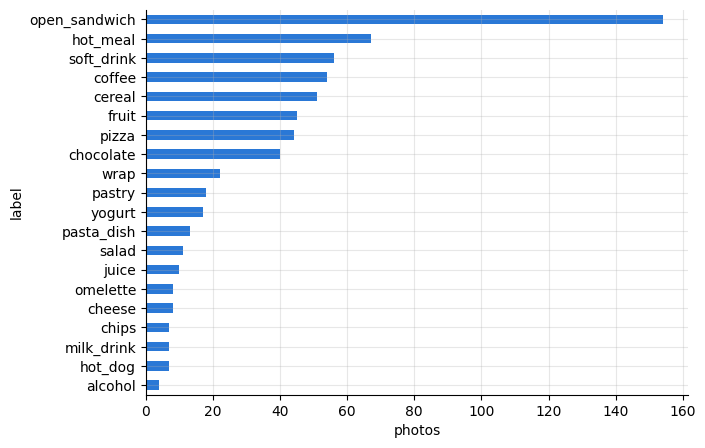

In [4]:
pred["label"].value_counts().plot.barh(figsize=(7, 5), color="#2a78d6").invert_yaxis()
plt.xlabel("photos");

## Calories estimées

Chaque classe a une portion type dont les calories viennent des valeurs USDA FoodData Central (par exemple une canette de cola de 330 ml à 42 kcal/100 ml donne 139 kcal). Pour une photo, je prends la moyenne des 3 classes les plus probables, pondérée par leur probabilité.

In [5]:
from src import food
from src.data import build_daily
daily = build_daily()[["participant", "date", "calories"]]
comp = food.daily_calories(pred).merge(daily, on=["participant", "date"])
comp.groupby("participant")[["food_n_photos", "food_kcal", "calories"]].median().round(0)

,food_n_photos,food_kcal,calories
participant,,,
p01,5.0,1349.0,3317.0
p03,2.0,638.0,2485.0
p05,3.0,813.0,3410.0


Les apports estimés restent bien en dessous de la dépense mesurée par Fitbit. Toutes les prises alimentaires ne sont sans doute pas photographiées, une photo ne compte qu'un aliment principal, et les portions sont standard. Les colonnes `food_*` de `test_dataset.csv` sont donc des ordres de grandeur (février et mars seulement) ; je ne les utilise pas dans les modèles.

Pour aller plus loin : estimer la taille des portions, reconnaître plusieurs aliments par photo, et annoter plus de photos pour l'évaluation.